<a href="https://colab.research.google.com/github/yiyangchen2020-afk/Problem-Set-5-Econ_3916_PS5.ipynb/blob/main/Econ_3916_PS5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Right 93% of the Time
ECON 3916 | Problem Set 5 | Yiyang Chen

## Phase 1: Build the Baseline Nobody Built

### Step 1.1: Simulate the loan data

In [15]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(42)
n = 10_000

X = pd.DataFrame({
    "income": np.clip(rng.lognormal(np.log(60_000), 0.45, n), 20_000, 250_000),
    "debt_to_income": rng.beta(3, 7, n),
    "credit_history_years": rng.integers(1, 31, n),
    "prior_delinquencies": rng.poisson(0.5, n),
    "loan_amount": np.clip(rng.lognormal(np.log(15_000), 0.55, n), 2_000, 65_000),
    "application_hour": rng.integers(0, 24, n),
    "application_month": rng.integers(1, 13, n),
    "form_version": rng.integers(1, 5, n),
})

# Only the five financial features affect the default probability.
log_odds = (
    -3.2
    - 0.25 * (X["income"] - 60_000) / 30_000
    + 0.65 * (X["debt_to_income"] - 0.30) / 0.15
    - 0.35 * (X["credit_history_years"] - 15) / 10
    + 0.75 * (X["prior_delinquencies"] - 0.5)
    + 0.35 * (X["loan_amount"] - 15_000) / 10_000
    + 0.60 * ((X["debt_to_income"] > 0.45) & (X["prior_delinquencies"] > 0))
)
default_prob = 1 / (1 + np.exp(-log_odds))
y = pd.Series(rng.binomial(1, default_prob), name="default")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)

print(f"Test applications: {len(y_test):,}")
print(f"Defaults in the test set: {y_test.sum():,}")
print(f"Test default rate: {y_test.mean():.2%}")

Test applications: 3,000
Defaults in the test set: 196
Test default rate: 6.53%


I simulated 10,000 loan applications and divided them into 70% training data and 30% test data before checking the results. The test set contained 3,000 applications and 196 defaults. The default rate was 6.53%. In the simulation, income, debt-to-income ratio, credit history length, number of prior delinquencies, and loan amount all affected the default risk. The application hour, application month, and form version were independently generated and had no impact on the default risk.

### Step 1.2: The null model

In [16]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

null_model = DummyClassifier(strategy="constant", constant=0)
null_model.fit(X_train, y_train)

null_pred = null_model.predict(X_test)
null_accuracy = accuracy_score(y_test, null_pred)

print(f"Null model test accuracy: {null_accuracy:.2%}")

Null model test accuracy: 93.47%


The null model predicts no default for every applicant. It gets 93.47% accuracy on the test set but misses all 196 defaults. This is the accuracy baseline for the other models. The vendor's 93% accuracy alone does not show that its model can identify applicants who will default.

## Phase 2: Fit and Regularise

### Step 2.1: Logistic regression and regularisation

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

logit = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=np.inf, max_iter=2000)
)
logit.fit(X_train, y_train)

logit_pred = logit.predict(X_test)
logit_accuracy = accuracy_score(y_test, logit_pred)
defaults_found = ((logit_pred == 1) & (y_test == 1)).sum()

print(f"Logistic regression test accuracy: {logit_accuracy:.2%}")
print(f"Defaults correctly flagged: {defaults_found} out of {y_test.sum()}")

Logistic regression test accuracy: 93.40%
Defaults correctly flagged: 8 out of 196


At the default threshold of 0.5, logistic regression had a test accuracy of 93.40%. This was slightly lower than the null model's accuracy of 93.47%. Logistic regression correctly flagged 8 of the 196 defaults. The null model flagged none.

In [18]:
from sklearn.model_selection import GridSearchCV

C_grid = {"logisticregression__C": np.logspace(-3, 2, 11)}
searches = {}

for name, penalty in [("LASSO", "l1"), ("Ridge", "l2")]:
    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            penalty=penalty, solver="saga", max_iter=2000, random_state=42
        )
    )
    search = GridSearchCV(model, C_grid, cv=5, scoring="neg_log_loss")
    search.fit(X_train, y_train)
    searches[name] = search

    best_C = search.best_params_["logisticregression__C"]
    test_accuracy = accuracy_score(y_test, search.predict(X_test))
    print(f"{name}: best C = {best_C:.4f}, test accuracy = {test_accuracy:.2%}")

# Choose the penalised model using cross-validation.
penalised_name = max(searches, key=lambda name: searches[name].best_score_)
penalised_model = searches[penalised_name].best_estimator_
penalised_pred = penalised_model.predict(X_test)

print(f"Selected penalised model: {penalised_name}")

LASSO: best C = 0.3162, test accuracy = 93.40%
Ridge: best C = 0.3162, test accuracy = 93.40%
Selected penalised model: LASSO


In [19]:
lasso = searches["LASSO"].best_estimator_
lasso_coef = pd.Series(lasso[-1].coef_[0], index=X_train.columns)

noise_features = {"application_hour", "application_month", "form_version"}
zero_features = set(lasso_coef[lasso_coef == 0].index)

print("Features set to zero:", sorted(zero_features))
print(f"Noise features removed: {len(zero_features & noise_features)} of 3")
print(f"True features removed: {len(zero_features - noise_features)} of 5")

Features set to zero: ['application_month']
Noise features removed: 1 of 3
True features removed: 0 of 5


LASSO and Ridge both selected a C of 0.3162 and had a test accuracy of 93.40%. LASSO had a slightly lower cross-validation log loss, so I selected it for the comparison with the random forest.

LASSO set the coefficient for application month to zero. It removed one of the three noise features and kept all five features that affect default risk in the simulation. LASSO penalizes the absolute size of the coefficients and can set some of them to zero. Ridge penalizes squared coefficients, which pulls them toward zero and typically keeps all the variables in the model. I would use LASSO when I want a smaller set of variables and Ridge when several related variables may all contain useful information.

### Step 2.2: Random forest

In [20]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=500, oob_score=True, bootstrap=True,
    random_state=42, n_jobs=-1
)
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)
rf_accuracy = accuracy_score(y_test, rf_pred)
penalised_accuracy = accuracy_score(y_test, penalised_pred)

print(f"Random forest OOB accuracy: {rf.oob_score_:.2%}")
print(f"Random forest OOB error: {1 - rf.oob_score_:.2%}")
print(f"Random forest test accuracy: {rf_accuracy:.2%}")
print(f"{penalised_name} test accuracy: {penalised_accuracy:.2%}")

Random forest OOB accuracy: 93.46%
Random forest OOB error: 6.54%
Random forest test accuracy: 93.50%
LASSO test accuracy: 93.40%


The out-of-bag accuracy rate of the random forest is 93.46%, the test accuracy rate is 93.50%, and its out-of-bag error is 6.54%. Both accuracy rates should be similar because each prediction is made by trees that did not train on that sample. If there is a large difference, it may indicate a discrepancy between the training data and the test data.

The test accuracy rate of the random forest is 93.50%, while that of LASSO is 93.40%. The difference is 0.10 percentage points, indicating that there were 3 more correct predictions out of 3,000 test samples. I will examine in Phase 4 whether this difference is statistically significant.

In [21]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    rf, X_test, y_test,
    scoring="average_precision", n_repeats=10, random_state=42
)

importance = pd.DataFrame({
    "MDI": rf.feature_importances_,
    "Permutation (AP drop)": perm.importances_mean
}, index=X_train.columns)

importance.sort_values("MDI", ascending=False).round(4)

,MDI,Permutation (AP drop)
debt_to_income,0.2246,0.1258
loan_amount,0.1814,0.0261
income,0.1689,0.0255
credit_history_years,0.1122,0.0002
application_hour,0.1110,-0.0114
application_month,0.0867,-0.0020
prior_delinquencies,0.0648,0.0787
form_version,0.0505,-0.0035


Debt-to-income ratio ranked first under both methods. Prior delinquencies ranked seventh by MDI and second by permutation importance. Application hour ranked above prior delinquencies by MDI, but shuffling application hour did not reduce average precision on the test set. MDI can give more weight to variables with many possible split points because the trees have more chances to find a split that looks useful in the training data.

Prior delinquencies helped the model predict default. Declining an application cannot change the applicant's past delinquencies. The lender can use that information to estimate risk when reviewing the application.

## Phase 3: The Number That Actually Matters

### Step 3.1: Beyond accuracy

LASSO confusion matrix (rows = actual, columns = predicted):
[[2794   10]
 [ 188    8]]
Random forest confusion matrix (rows = actual, columns = predicted):
[[2798    6]
 [ 189    7]]


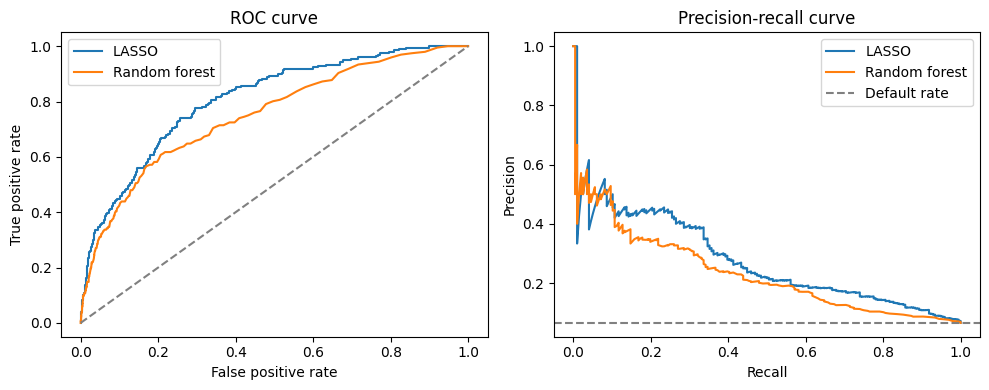

,Precision,Recall,F1,ROC AUC,PR AUC
Model,,,,,
LASSO,0.4444,0.0408,0.0748,0.8059,0.2748
Random forest,0.5385,0.0357,0.0670,0.7512,0.2319


In [22]:
import matplotlib.pyplot as plt
from sklearn import metrics

y_prob = penalised_model.predict_proba(X_test)[:, 1]
rf_prob = rf.predict_proba(X_test)[:, 1]

results = []
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for name, pred, prob in [
    (penalised_name, penalised_pred, y_prob),
    ("Random forest", rf_pred, rf_prob)
]:
    cm = metrics.confusion_matrix(y_test, pred)
    print(f"{name} confusion matrix (rows = actual, columns = predicted):")
    print(cm)

    fpr, tpr, _ = metrics.roc_curve(y_test, prob)
    precision, recall, _ = metrics.precision_recall_curve(y_test, prob)

    results.append({
        "Model": name,
        "Precision": metrics.precision_score(y_test, pred),
        "Recall": metrics.recall_score(y_test, pred),
        "F1": metrics.f1_score(y_test, pred),
        "ROC AUC": metrics.roc_auc_score(y_test, prob),
        "PR AUC": metrics.auc(recall, precision)
    })

    axes[0].plot(fpr, tpr, label=name)
    axes[1].plot(recall, precision, label=name)

axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[1].axhline(y_test.mean(), linestyle="--", color="gray", label="Default rate")

axes[0].set(title="ROC curve", xlabel="False positive rate", ylabel="True positive rate")
axes[1].set(title="Precision-recall curve", xlabel="Recall", ylabel="Precision")

for ax in axes:
    ax.legend()

plt.tight_layout()
plt.show()

pd.DataFrame(results).set_index("Model").round(4)

At the 0.5 threshold, LASSO correctly identified 8 out of 196 defaults, while the random forest identified 7. Their recall rates were 4.08% and 3.57%, respectively. At this threshold, the random forest had higher precision. LASSO had higher ROC AUC and PR AUC than the random forest.

The default rate in the test set was 6.53%. Since the number of non-defaults was much larger than the number of defaults, even with a low false positive rate, there could still be a large number of false positives. Therefore, even if precision is low, the ROC curve may still look good. The precision-recall curve shows what proportion of flagged applicants actually defaulted as the model identified more defaults. I chose to use LASSO for cost analysis because it is simpler and has a higher PR AUC. At the 0.5 threshold, the random forest made one more correct prediction than the approve-all baseline, while LASSO made two fewer.

### Step 3.2: Put a price on being wrong

For a false negative, I count 60% of the loan principal as a loss. For a false positive, I count 8% of the principal as lost interest margin plus $200 in reputational cost. I use $200 as an assumed cost of lost goodwill when a good applicant is wrongly declined.

Threshold selected by cross-validation: 0.126
Distance below 0.5: 0.374
Lowest point on the test curve: 0.129


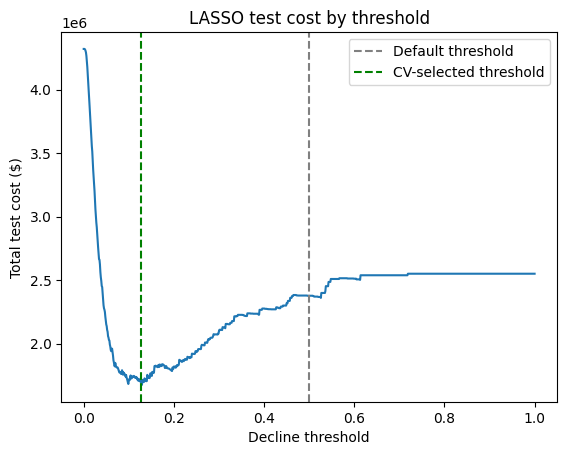

,Threshold,TN,FP,FN,TP,Test cost ($)
Policy,,,,,,
Approve all,1.000,2804,0,196,0,2550834.272
Default threshold,0.500,2794,10,188,8,2377393.958
CV-selected threshold,0.126,2521,283,108,88,1713632.137


In [23]:
from sklearn.model_selection import cross_val_predict

train_prob = cross_val_predict(
    penalised_model, X_train, y_train, cv=5, method="predict_proba"
)[:, 1]

principal_train = X_train["loan_amount"].to_numpy()
principal_test = X_test["loan_amount"].to_numpy()
reputation_cost = 200
thresholds = np.linspace(0, 1, 1001)

def expected_cost(t, prob, y, principal, fn_rate=0.60):
    decline = prob >= t
    fn = (y == 1) & ~decline
    fp = (y == 0) & decline
    return (fn_rate * principal[fn]).sum() + (0.08 * principal[fp] + reputation_cost).sum()

def cost_curve(prob, y, principal, fn_rate=0.60):
    return [expected_cost(t, prob, y, principal, fn_rate) for t in thresholds]

train_costs = cost_curve(train_prob, y_train, principal_train)
best_t = thresholds[np.argmin(train_costs)]

test_costs = cost_curve(y_prob, y_test, principal_test)
test_best_t = thresholds[np.argmin(test_costs)]

print(f"Threshold selected by cross-validation: {best_t:.3f}")
print(f"Distance below 0.5: {0.5 - best_t:.3f}")
print(f"Lowest point on the test curve: {test_best_t:.3f}")

plt.plot(thresholds, test_costs)
plt.axvline(0.5, linestyle="--", color="gray", label="Default threshold")
plt.axvline(best_t, linestyle="--", color="green", label="CV-selected threshold")
plt.xlabel("Decline threshold")
plt.ylabel("Total test cost ($)")
plt.title("LASSO test cost by threshold")
plt.legend()
plt.show()

rows = []
for policy, t in [("Approve all", 1.0), ("Default threshold", 0.5), ("CV-selected threshold", best_t)]:
    tn, fp, fn, tp = metrics.confusion_matrix(y_test, y_prob >= t).ravel()
    rows.append({
        "Policy": policy, "Threshold": t,
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "Test cost ($)": expected_cost(t, y_prob, y_test, principal_test)
    })

pd.DataFrame(rows).set_index("Policy").round(3)

In [24]:
sensitivity = []
example_principal = 15_000

for fn_rate in [0.30, 0.60, 0.90]:
    costs = cost_curve(train_prob, y_train, principal_train, fn_rate)
    t = thresholds[np.argmin(costs)]
    cost_ratio = fn_rate * example_principal / (0.08 * example_principal + reputation_cost)

    sensitivity.append({
        "Default loss (% of principal)": 100 * fn_rate,
        "FN-to-FP cost ratio ($15,000 loan)": cost_ratio,
        "CV-selected threshold": t
    })

pd.DataFrame(sensitivity).round(3)

,Default loss (% of principal),"FN-to-FP cost ratio ($15,000 loan)",CV-selected threshold
0,30.0,3.214,0.237
1,60.0,6.429,0.126
2,90.0,9.643,0.103


The cost-minimizing threshold obtained through cross-validation is 0.126, which is 0.374 lower than 0.5. The test cost curve reaches its lowest point at a threshold of 0.129. I used the cross-validation threshold to evaluate the performance of this strategy on the test set.

When the threshold was set at 0.126, the false negatives decreased from 188 to 108, and the false positives increased from 10 to 283. The test cost decreased from 2377394 dollars at the 0.5 threshold to 1713632 dollars at the 0.126 threshold, saving approximately 663762 dollars compared to the 0.5 threshold and 837202 dollars compared to approving all applications.

When the default loss rate increased from 30% of the principal to 60%, and then to 90%, the selected threshold decreased from 0.237 to 0.126, and then to 0.103. When the cost of missing a default rises relative to the cost of wrongly rejecting a qualified applicant, the lending institution should lower the threshold. If the cost of wrongly rejecting a qualified applicant rises relative to the cost of missing a default, the threshold should be raised.

## Phase 4: AI Expansion — The Co-Pilot Era

### Task 4.1 Part A: Comparing the two models

In [25]:
from scipy.stats import binomtest

actual = y_test.to_numpy()
rf_correct = rf_pred == actual
lasso_correct = penalised_pred == actual

b = (rf_correct & ~lasso_correct).sum()
c = (~rf_correct & lasso_correct).sum()

agreement = pd.DataFrame(
    [[(rf_correct & lasso_correct).sum(), b],
     [c, (~rf_correct & ~lasso_correct).sum()]],
    index=["Forest correct", "Forest wrong"],
    columns=["LASSO correct", "LASSO wrong"]
)

display(agreement)
print(f"b = {b}, c = {c}, b + c = {b + c}")

p_value = binomtest(b, b + c, p=0.5, alternative="two-sided").pvalue
print(f"Exact McNemar p-value: {p_value:.4f}")

,LASSO correct,LASSO wrong
Forest correct,2795,10
Forest wrong,7,188


b = 10, c = 7, b + c = 17
Exact McNemar p-value: 0.6291


The random forest was correct on 10 applications that LASSO got wrong, while LASSO was correct on 7 applications that the random forest got wrong. Since the two models differed in correctness on only 17 applications, I used the exact McNemar test, and its two-sided p-value was 0.6291. Although the test accuracy of the random forest was slightly higher, this difference was not statistically significant at the 5% significance level.

The McNemar test is used to compare the number of errors. Comparing dollar costs would better reflect the lending decision. I suggest resampling the same test applicants for both models and comparing the costs on these paired rows.

### Task 4.1 Part B: Checking calibration

In [26]:
from sklearn.isotonic import IsotonicRegression

def log_odds(prob):
    prob = np.clip(prob, 1e-6, 1 - 1e-6)
    return np.log(prob / (1 - prob)).reshape(-1, 1)

platt = LogisticRegression(C=1e6)
platt.fit(log_odds(train_prob), y_train)

isotonic = IsotonicRegression(out_of_bounds="clip")
isotonic.fit(train_prob, y_train)

calibration_probs = {
    "Raw LASSO": y_prob,
    "Platt": platt.predict_proba(log_odds(y_prob))[:, 1],
    "Isotonic": isotonic.predict(y_prob)
}

Raw LASSO


,Count,Mean predicted,Observed rate
0,750,0.0129,0.0107
1,1061,0.0330,0.0245
2,674,0.0706,0.0801
3,244,0.1223,0.1230
4,109,0.1729,0.1468
5,93,0.2410,0.3441
6,69,0.4263,0.4348


Platt


,Count,Mean predicted,Observed rate
0,765,0.0128,0.0105
1,1051,0.0329,0.0247
2,670,0.0706,0.0821
3,242,0.1224,0.1198
4,108,0.1728,0.1296
5,93,0.2402,0.3548
6,71,0.4261,0.4366


Isotonic


,Count,Mean predicted,Observed rate
0,727,0.0107,0.0110
1,1026,0.0337,0.0234
2,876,0.0704,0.0868
3,259,0.1714,0.1506
4,112,0.3971,0.4375


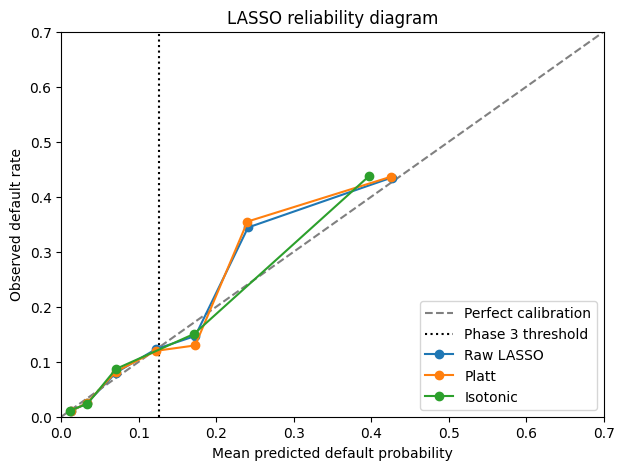

,Brier score,Reliability,Resolution,Uncertainty,Within-bin correction
Method,,,,,
Raw LASSO,0.053891,0.000403,0.007445,0.061065,-0.000132
Platt,0.053883,0.000532,0.007657,0.061065,-0.000057
Isotonic,0.054083,0.000212,0.007249,0.061065,0.000055


In [27]:
def calibration_bins(prob, actual):
    order = np.argsort(prob)
    prob, actual = prob[order], actual[order]
    cuts = np.searchsorted(prob, [0.02, 0.05, 0.10, 0.15, 0.20, 0.30])

    bounds = [0]
    for cut in cuts:
        if cut - bounds[-1] >= 50:
            bounds.append(cut)
    if len(bounds) > 1 and len(prob) - bounds[-1] < 50:
        bounds.pop()
    bounds.append(len(prob))

    return pd.DataFrame([
        {"Count": end - start,
         "Mean predicted": prob[start:end].mean(),
         "Observed rate": actual[start:end].mean()}
        for start, end in zip(bounds[:-1], bounds[1:])
    ])

actual = y_test.to_numpy()
base_rate = actual.mean()
uncertainty = base_rate * (1 - base_rate)
summary = []

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot([0, 0.7], [0, 0.7], "--", color="gray", label="Perfect calibration")
ax.axvline(best_t, linestyle=":", color="black", label="Phase 3 threshold")

for name, prob in calibration_probs.items():
    bins = calibration_bins(prob, actual)
    weight = bins["Count"] / len(actual)
    reliability = (weight * (bins["Mean predicted"] - bins["Observed rate"]) ** 2).sum()
    resolution = (weight * (bins["Observed rate"] - base_rate) ** 2).sum()
    brier = metrics.brier_score_loss(actual, prob)
    correction = brier - (reliability - resolution + uncertainty)

    summary.append({
        "Method": name, "Brier score": brier,
        "Reliability": reliability, "Resolution": resolution,
        "Uncertainty": uncertainty, "Within-bin correction": correction
    })

    ax.plot(bins["Mean predicted"], bins["Observed rate"], "o-", label=name)
    print(name)
    display(bins.round(4))

ax.set(xlabel="Mean predicted default probability",
       ylabel="Observed default rate",
       title="LASSO reliability diagram",
       xlim=(0, 0.7), ylim=(0, 0.7))
ax.legend()
plt.show()

display(pd.DataFrame(summary).set_index("Method").round(6))

The Brier scores of the original LASSO, Platt scaling, and isotonic regression are 0.053891, 0.053883, and 0.054083, respectively. Platt scaling reduces the Brier score by approximately 0.000008, while isotonic regression increases it. In the original LASSO probability bin that covers the 0.126 threshold, the average predicted default rate across 244 applications is 12.23%, and the observed rate is 12.30%. Based on these results, I decided to retain the original LASSO probabilities and the 0.126 threshold in this analysis.

Even if the probabilities estimated by the model are too high or too low, as long as the model ranks the applicants well, it may still have a high AUC value. Calibration is crucial because the same numerical threshold may flag different applicants after the probabilities are adjusted.

### AI Transcript

#### Part A

**Model:** GPT-6.2 Sol  
**Date:** November 24, 2026

**Original prompt**

[Prep] Act as a model risk analyst comparing two candidate credit
models before one goes into production.

[Request] I have two fitted classifiers scored on my test set. The
random forest got 0.9?? accuracy and the penalised logistic model got
0.9??. Write Python that tells me whether the forest is significantly
better, and give me a p-value.

[Iterate] numpy, pandas and scipy only. Reuse my y_test, my two
prediction arrays, and nothing else.

[Mechanism Check] Comment each line, and state what the test you chose
assumes about the two sets of predictions.

[Evaluate] One sentence I can put in front of the head of risk.

**Original AI reply**

Use a **one-sided exact McNemar test** to check whether the random forest has higher test-set accuracy. It compares the number of cases only the forest classified correctly with the number only the penalised logistic model classified correctly. The rounded accuracies alone don’t give those counts, so run this on your three arrays to get the p-value.

I’ve used `y_pred_rf` and `y_pred_logit` as the prediction array names and 5% as the significance level.

```python
import numpy as np  # Convert inputs to arrays and compare them row by row.
import pandas as pd  # Check for missing labels or predictions.
from scipy.stats import binomtest  # Compute the exact one-sided p-value.

actual = np.asarray(y_test)  # Use your existing test labels.
forest = np.asarray(y_pred_rf)  # Use your existing random forest predictions.
logit = np.asarray(y_pred_logit)  # Use your existing penalised logistic predictions.

if actual.ndim != 1 or actual.size == 0 or forest.shape != actual.shape or logit.shape != actual.shape:  # Require three nonempty vectors of equal length.
    raise ValueError("Provide three nonempty, one-dimensional arrays of equal length.")  # Stop if the input shapes are incompatible.
if any(pd.isna(values).any() for values in (actual, forest, logit)):  # Check all three arrays for missing values.
    raise ValueError("Test labels and predictions must have no missing values.")  # Stop before missing values can distort the counts.

forest_correct = forest == actual  # Mark cases the forest classified correctly.
logit_correct = logit == actual  # Mark cases the logistic model classified correctly.
forest_only = int(np.sum(forest_correct & ~logit_correct))  # Count cases only the forest got right.
logit_only = int(np.sum(logit_correct & ~forest_correct))  # Count cases only the logistic model got right.
discordant = forest_only + logit_only  # Count cases where exactly one model was right.

p_value = binomtest(forest_only, discordant, p=0.5, alternative="greater").pvalue if discordant else 1.0  # Under equal accuracy, either model is equally likely to win a discordant case.
gap_pp = 100 * (forest_only - logit_only) / actual.size  # Compute the forest's accuracy minus the logistic model's in percentage points.

print(f"Forest-only correct: {forest_only}, logistic-only correct: {logit_only}, p-value: {p_value:.6g}")  # Report the paired counts and p-value.
print(f"The random forest's test accuracy was {gap_pp:+.2f} percentage points relative to penalised logistic regression, with {'statistically significant evidence' if p_value < 0.05 else 'insufficient evidence'} of higher accuracy (one-sided exact McNemar p = {p_value:.4g}).")  # Print one sentence for the head of risk.
```

**Assumptions.** Both arrays contain predicted class labels for the same test cases in the same order as `y_test`. The predictions within each case are paired and may be correlated. The test assumes independence **across** cases, which can fail if the test set contains multiple loans from the same borrower. Use the one-sided p-value if you chose to test whether the forest was better before seeing these test results. If you picked that direction after seeing which model scored higher, change `alternative="greater"` to `alternative="two-sided"` and report whether the accuracies differ.

**Changes I made**

- The AI used a one-sided exact McNemar test. It treated the two predictions for each applicant as paired and assumed independence across applicants.
- I used `rf_pred` and `penalised_pred` to match the arrays in my notebook.
- I added the full 2×2 table and reported `b + c`.
- I used a two-sided test because I had already compared the test accuracies in Step 2.2.

#### Part B

**Model:** GPT-6.2 Sol   
**Date:** November 24, 2026

**Original prompt**

[Prep] Act as a model risk analyst at a bank, reviewing a credit
scoring model before it goes into production.

[Request] I have a fitted classifier producing default probabilities
on a test set with about 7% prevalence. Write Python that assesses
CALIBRATION -- a reliability diagram binning predicted probability
against observed frequency, plus the Brier score and its
decomposition -- and then applies both Platt scaling and isotonic
regression, reporting whether either improves calibration.

[Iterate] scikit-learn, numpy, matplotlib. Reuse my y_test and
y_prob. Handle the sparse high-probability bins that low prevalence
creates rather than letting them produce a misleading plot.

[Mechanism Check] Explain why a model can rank applicants correctly --
high AUC -- and still be badly calibrated, and why that distinction
decides whether my cost-optimal threshold is trustworthy.

[Evaluate] Given my reliability diagram, is my Phase 3 threshold
valid? If not, what should I do before using it?

**Original AI reply**

**I would keep your Phase 3 cutoff of 0.126 as a candidate, pending validation.** You haven’t shared the reliability diagram or its bin counts, so I can’t tell how well the raw scores estimate default risk near 0.126. Since you selected the cutoff by minimizing cost in cross-validation, the decisive check is whether the **fixed cutoff** delivers acceptable realized cost on untouched data. The diagram answers a separate question: whether a score near 0.126 can be read as roughly a 12.6% probability of default. [scikit-learn 1.9.1 documentation](https://scikit-learn.org/stable/modules/calibration?utm_source=chatgpt.com)

### Python

This uses only `y_test` and `y_prob`. It assumes `1` means default, the arrays are aligned, and the base classifier was fitted without these rows. A stratified 50/50 split fits both calibrators on one half and compares all three methods on the same evaluation half. The diagram merges adjacent bins with fewer than 50 cases, shows the score range and an approximate 95% Wilson interval for each bin, and prints the actual default count. If the evaluation sample itself has fewer than 50 cases, it shows a single bin. [scikit-learn 1.9.1 documentation](https://scikit-learn.org/stable/modules/calibration?utm_source=chatgpt.com)

```python
import numpy as np
import matplotlib.pyplot as plt
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

y = np.asarray(y_test)
p = np.asarray(y_prob, dtype=float)

if y.ndim != 1 or p.shape != y.shape:
    raise ValueError("Use aligned 1-D arrays of labels and default probabilities.")
if not np.array_equal(np.unique(y), [0, 1]):
    raise ValueError("Use binary labels with 1 = default and 0 = no default.")
if not np.isfinite(p).all() or np.any((p < 0) | (p > 1)):
    raise ValueError("Default probabilities must be finite and between 0 and 1.")

y = y.astype(int)
if np.bincount(y).min() < 2:
    raise ValueError("At least two observations of each class are needed to split.")

fit, evaluate = train_test_split(
    np.arange(y.size), test_size=0.5, stratify=y, random_state=42
)
y_eval = y[evaluate]
raw = p[evaluate]
base_rate = y_eval.mean()

# Fit a Platt-style sigmoid using log-odds as the input score.
clipped = np.clip(p, 1e-6, 1 - 1e-6)
log_odds = (np.log(clipped) - np.log1p(-clipped)).reshape(-1, 1)
platt = LogisticRegression(C=1e6, solver="lbfgs")
platt.fit(log_odds[fit], y[fit])

# Fit a monotone, nonparametric calibration map.
isotonic = IsotonicRegression(out_of_bounds="clip")
isotonic.fit(p[fit], y[fit])

forecasts = {
    "Raw": raw,
    "Platt": platt.predict_proba(log_odds[evaluate])[:, 1],
    "Isotonic": isotonic.predict(raw),
}

def reliability_bins(scores, outcomes, min_count=50):
    """Merge neighboring 0.05-wide bins until they have enough cases."""
    order = np.argsort(scores)
    sorted_scores, sorted_outcomes = scores[order], outcomes[order]
    cuts = np.searchsorted(sorted_scores, np.linspace(0.05, 0.95, 19))
    bounds = [0]
    for cut in cuts:
        if cut - bounds[-1] >= min_count:
            bounds.append(cut)
    if len(bounds) > 1 and len(scores) - bounds[-1] < min_count:
        bounds.pop()  # Combine a sparse upper tail with the previous bin.
    bounds.append(len(scores))

    rows = []
    for start, stop in zip(bounds[:-1], bounds[1:]):
        s = sorted_scores[start:stop]
        events = sorted_outcomes[start:stop].sum()
        rows.append((s.size, events, s.mean(), s[0], s[-1]))
    return np.asarray(rows, dtype=float)

# Use paired evaluation losses so every comparison uses the same applicants.
names = list(forecasts)
losses = np.column_stack([(scores - y_eval) ** 2 for scores in forecasts.values()])
differences = losses[:, 1:] - losses[:, [0]]
rng = np.random.default_rng(42)
boot = np.empty((2000, 2))
for i in range(len(boot)):
    sample = rng.integers(0, len(y_eval), size=len(y_eval))
    boot[i] = differences[sample].mean(axis=0)

# Two 97.5% intervals give approximately 95% family-wise coverage.
ci_low, ci_high = np.quantile(boot, [0.0125, 0.9875], axis=0)

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharex=True, sharey=True)
print(f"Defaults: {y[fit].sum()} in calibration, "
      f"{y_eval.sum()} in evaluation ({base_rate:.1%} prevalence)")
uncertainty = base_rate * (1 - base_rate)
print(f"Constant-prevalence Brier reference: {uncertainty:.6f}")
reliability = {}

for j, (ax, (name, scores)) in enumerate(zip(axes, forecasts.items())):
    n, events, mean_p, p_min, p_max = reliability_bins(scores, y_eval).T
    observed = events / n
    weight = n / len(y_eval)

    # Murphy decomposition for bin-mean forecasts, plus the raw-score correction.
    reliability[name] = np.sum(weight * (mean_p - observed) ** 2)
    resolution = np.sum(weight * (observed - base_rate) ** 2)
    binned_brier = reliability[name] - resolution + uncertainty
    brier = losses[:, j].mean()
    within_bin = brier - binned_brier

    print(f"\n{name}: Brier={brier:.6f}, reliability={reliability[name]:.6f}, "
          f"resolution={resolution:.6f}, uncertainty={uncertainty:.6f}, "
          f"within-bin correction={within_bin:+.6f}")
    for count, defaults, lower, upper, avg, rate in zip(
        n, events, p_min, p_max, mean_p, observed
    ):
        print(f"  Scores {lower:.3f}–{upper:.3f}: {int(defaults)}/{int(count)} "
              f"defaults, mean predicted {avg:.1%}, observed {rate:.1%}")

    # Wilson intervals for the observed frequencies, including zero-default bins.
    z = 1.96
    denominator = 1 + z**2 / n
    center = (observed + z**2 / (2 * n)) / denominator
    radius = z * np.sqrt(observed * (1 - observed) / n + z**2 / (4 * n**2))
    radius /= denominator

    ax.plot([0, 1], [0, 1], "--", color="0.65", label="Perfect calibration")
    ax.hlines(observed, p_min, p_max, color="C0", alpha=0.55)
    ax.vlines(mean_p, center - radius, center + radius, color="C0")
    ax.scatter(mean_p, observed, color="C0", zorder=3)
    if name == "Raw":
        ax.axvline(0.126, color="C3", linestyle=":", label="Phase 3 cutoff")
        ax.legend(loc="upper left", fontsize=8)
    ax.set(title=name, xlabel="Mean predicted default probability",
           xlim=(0, 1), ylim=(0, 1))

axes[0].set_ylabel("Observed default frequency")
fig.tight_layout()
plt.show()

for j, name in enumerate(names[1:]):
    change = differences[:, j].mean()
    lower, upper = ci_low[j], ci_high[j]
    if upper < 0 and reliability[name] < reliability["Raw"]:
        verdict = "Evidence supports improved calibration."
    elif lower > 0:
        verdict = "Brier score worsened."
    elif upper < 0:
        verdict = "Brier score improved, but binned reliability did not."
    else:
        verdict = "Improvement is inconclusive."
    print(f"{name}: ΔBrier={change:+.6f}, "
          f"97.5% paired CI [{lower:+.6f}, {upper:+.6f}]. {verdict}")
```

The reported identity is **Brier = reliability − resolution + uncertainty + within-bin correction**. Lower reliability means smaller discrepancies between predicted and observed default rates. Higher resolution means the bins separate groups with different default rates. The correction accounts for replacing individual scores with bin means. Because bin boundaries can differ between methods, treat reliability changes as descriptive and use the diagrams alongside the paired Brier comparison. The bootstrap assumes independent evaluation rows and measures uncertainty conditional on the fitted calibrators. [scikit-learn 1.9.1 documentation](https://scikit-learn.org/stable/modules/calibration?utm_source=chatgpt.com)

### What this means for Phase 3

- **High AUC can coexist with poor calibration.** Squaring every probability preserves every ranking and therefore preserves AUC. It also turns a 20% prediction into 4%. A decision rule that uses probabilities to estimate expected dollar losses depends on that numerical difference. [scikit-learn 1.9.1 documentation](https://scikit-learn.org/stable/modules/calibration?utm_source=chatgpt.com)
- **Check support around 0.126.** If the raw-score bin spanning the cutoff is wide or its observed default rate has a wide interval, the plot has limited power to assess calibration there. A pooled bin can also hide different behavior on either side of the cutoff.
- **Before using the policy, lock the score scale and cutoff, then validate realized cost on an untouched, preferably later sample.** If you keep raw scores, evaluate the fixed 0.126 rule. If you adopt Platt or isotonic, reselect the cutoff on the calibrated scale using your Phase 3 cost function on development data, then evaluate that locked policy independently. If the current test set helps you choose the calibration method, use fresh data for final validation. [scikit-learn 1.9.1 documentation](https://scikit-learn.org/stable/modules/calibration?utm_source=chatgpt.com)

**Changes I made**

- I fitted both calibrators on out-of-fold probabilities from the training set and evaluated all three methods on the full original test set. The AI had split the test set to fit and evaluate the calibrators.
- I merged sparse probability bins and displayed their counts. I simplified the comparison by using the reliability diagram and Brier scores without the confidence intervals and bootstrap.
- I checked the raw probability bin containing 0.126 and used the calibration results to decide whether to keep the Phase 3 cutoff.

### Task 4.2: Recommendation to the Head of Risk

I suggest postponing the signing of the supplier contract. The accuracy rate reported by this supplier is 93%. Approving all applications yielded an accuracy rate of 93.47% on the simulation test set, and all 196 cases of default were missed.

I suggest testing the real loan data using the LASSO model and setting the rejection threshold at 0.126. In the simulation test set, this threshold successfully identified 88 out of 196 default cases and wrongly rejected 283 applicants who did not default. I assume that each missed default will result in a 60% loss of principal and that each incorrect rejection will cost 8% of principal in lost interest margin and $200 in lost goodwill. Based on these assumptions, compared to approving all applications, this threshold saved approximately 837202 dollars on the simulation test set. Calibration checks support the retention of the original LASSO probabilities and the 0.126 threshold in this analysis.

If the supplier's model uses a pre-set threshold on an independent set of recent loan applications and costs less than approving all applications, I will reconsider whether to sign the contract.